# Fase 4 (extra): control Monte Carlo

Los resultados se calculan con `python scripts/fase4_montecarlo.py` (unos 47 minutos con 16 procesos) y se guardan en `results/fase4_mc_*.csv`. Este notebook solo los lee, salvo la medida del coste por episodio de la sección 4.

**Qué es.** Control Monte Carlo *on-policy* con política ε-greedy (slides 2, *On-Policy First-Visit MC Control*). Comparte con Sarsa todo salvo el objetivo de la actualización:

- **Sarsa (TD):** $Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha\,[R_{t+1} + \gamma Q(S_{t+1},A_{t+1}) - Q(S_t,A_t)]$, en cada paso.
- **Monte Carlo:** $Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha\,[G_t - Q(S_t,A_t)]$, al acabar el episodio, con el retorno real $G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \dots$

Con $\alpha = 1/n$, $Q$ es el promedio de los retornos, como en el algoritmo de las slides. Probamos las dos variantes de las slides: **primera visita** (solo cuenta la primera aparición de cada par $(s,a)$ en el episodio) y **todas las visitas**. La implementación está en `rl_trader/agents.py` (`actualizar_montecarlo`).

**Por qué tiene sentido aquí: las slides hacen dos predicciones opuestas.**

- **A favor de MC:** "la estimación MC no se ve afectada si los estados subsecuentes no cumplen estrictamente la propiedad de Markov" (slides 2). Nuestro estado no es markoviano: la tendencia de 6 pasos no ve la distancia a la media de largo plazo (reversión) ni el régimen oculto (regímenes). TD hace *bootstrap* sobre $Q(S_{t+1},\cdot)$ como si lo fuera.
- **En contra de MC:** "a medida que la longitud de los episodios aumenta, la varianza del retorno $G_t$ escala sustancialmente" (slides 2). Nuestros episodios tienen 495 pasos y retornos con un 1–10% de ruido por paso; con $\gamma$ alto, $G_t$ suma decenas de esos ruidos.
- **Control:** con $\gamma = 0$, $G_t = R_{t+1}$ y MC tiene exactamente el mismo objetivo que TD. En ciclo y browniano, donde la fase 2 eligió $\gamma = 0$, no debería haber diferencias.

**Protocolo.** El mismo de las fases 2 y 3, para que la comparación sea justa:

- **Ajuste en validación** (3 semillas × 100 series, 2000 episodios; 660 entrenamientos). Etapa A: tasa de aprendizaje (5 opciones) × $\gamma$ (4) × visita (2). Etapa B: nº de intervalos (5) × calendario de $\varepsilon$ (3).
- **Test:** 10 semillas nuevas (100–109), 4000 episodios y las mismas 100 series de test que el resto de agentes.
- **Experimento controlado:** MC con exactamente los hiperparámetros elegidos para Sarsa en la fase 2. Con todo lo demás igual, solo cambia el objetivo: retorno real frente a *bootstrap*.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

import rl_trader
from rl_trader.agents import Discretizador
from rl_trader.baselines import BASELINES
from rl_trader.evaluation import SEMILLA_VALIDACION, evaluar, generar_series, ic_bootstrap_pareado

from rl_trader.plots import (COLORES_ALGORITMO, EJE, FONDO, NOMBRES_ALGORITMO, NOMBRES_MERCADO, SECUENCIAL,
                             TINTA_2, aplicar_estilo, compacto, corto)
from rl_trader.prices import GENERADORES

aplicar_estilo()
ROOT = Path(rl_trader.__file__).resolve().parent.parent
RESULTADOS, FIGURAS = ROOT / "results", ROOT / "figures"
MERCADOS = list(NOMBRES_MERCADO)
ALGOS = ["qlearning", "sarsa", "montecarlo"]

# Fase 3 (Q-learning, Sarsa y referencias) y fase 4 (Monte Carlo), con los run renumerados
runs3 = pd.read_csv(RESULTADOS / "fase3_entrenamientos.csv", dtype={"politica": str})
runs4 = pd.read_csv(RESULTADOS / "fase4_mc_entrenamientos.csv", dtype={"politica": str})
runs4["run"] += 10_000
curvas = pd.concat([pd.read_csv(RESULTADOS / "fase3_curvas.csv", dtype={"politica": str}),
                    pd.read_csv(RESULTADOS / "fase4_mc_curvas.csv", dtype={"politica": str})
                    .assign(run=lambda d: d["run"] + 10_000)])
runs = pd.concat([runs3, runs4], ignore_index=True)
curvas = curvas.merge(runs[["run", "mercado", "agente", "seed"]], on="run")
test = pd.concat([pd.read_csv(RESULTADOS / "fase3_test_por_serie.csv"),
                  pd.read_csv(RESULTADOS / "fase4_mc_test_por_serie.csv")], ignore_index=True)
test["log_capital"] = np.log1p(test["retorno_pct"] / 100)

ETIQUETAS = {"aleatorio": "Aleatorio", "buy_and_hold": "Buy & hold", "momentum": "Momentum",
             "contrarian": "Contrarian", "qlearning": "Q-learning", "sarsa": "Sarsa", "montecarlo": "Monte Carlo",
             "montecarlo (config. sarsa)": "Monte Carlo (config. Sarsa)"}
print(f"{len(runs4)} entrenamientos de Monte Carlo; {test.shape[0]} episodios de test en total")

80 entrenamientos de Monte Carlo; 29200 episodios de test en total


## 1. Ajuste en validación: ¿cómo responde MC a $\gamma$?

Para cada $\gamma$, la mejor mediana de validación entre las 5 tasas de aprendizaje (media de 3 semillas, etapa A). Q-learning y Sarsa salen de la etapa A de la fase 2, con el mismo protocolo.

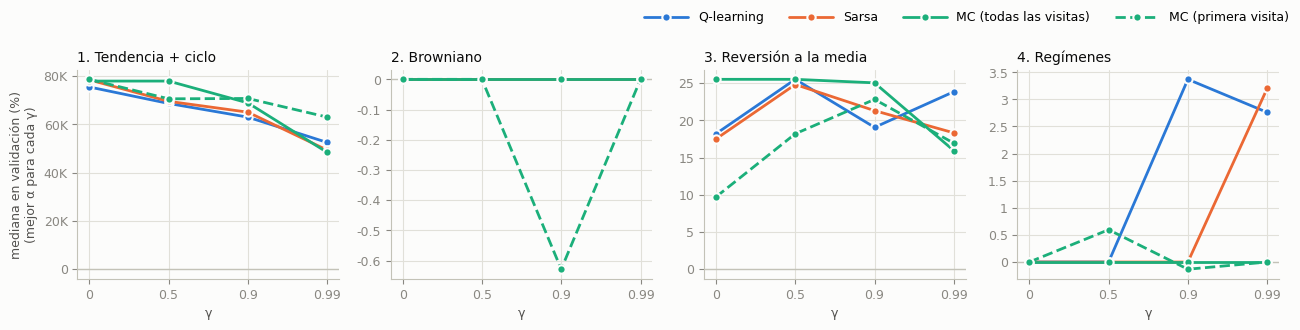

gamma                 0.0  0.5  0.9  1.0
mercado   algoritmo                     
browniano mc_primera  0.0  0.0 -0.6  0.0
          montecarlo  0.0  0.0  0.0  0.0
          qlearning   0.0  0.0  0.0  0.0
          sarsa       0.0  0.0  0.0  0.0
ciclo     mc_primera  79K  71K  71K  63K
          montecarlo  78K  78K  69K  48K
          qlearning   76K  69K  63K  53K
          sarsa       78K  70K  65K  49K
regimenes mc_primera  0.0  0.6 -0.1  0.0
          montecarlo  0.0  0.0  0.0  0.0
          qlearning   0.0  0.0  3.4  2.8
          sarsa       0.0  0.0  0.0  3.2
reversion mc_primera  9.7 18.2 22.8 16.9
          montecarlo 25.5 25.5 25.0 15.9
          qlearning  18.2 25.5 19.1 23.8
          sarsa      17.5 24.8 21.3 18.3


In [2]:
td = pd.read_csv(RESULTADOS / "fase2_etapa_a.csv")
mc = pd.read_csv(RESULTADOS / "fase4_mc_etapa_a.csv")
mc["algoritmo"] = np.where(mc["primera_visita"], "mc_primera", "montecarlo")
etapa_a = pd.concat([td, mc], ignore_index=True)
# Mediana de validación media entre semillas; para cada γ, la mejor tasa de aprendizaje
por_config = etapa_a.groupby(["mercado", "algoritmo", "gamma", "alpha", "omega"])["val_mediana"].mean()
mejor_por_gamma = por_config.groupby(["mercado", "algoritmo", "gamma"]).max().unstack("gamma")

VARIANTES = {"qlearning": ("Q-learning", COLORES_ALGORITMO["qlearning"], "-"),
             "sarsa": ("Sarsa", COLORES_ALGORITMO["sarsa"], "-"),
             "montecarlo": ("MC (todas las visitas)", COLORES_ALGORITMO["montecarlo"], "-"),
             "mc_primera": ("MC (primera visita)", COLORES_ALGORITMO["montecarlo"], "--")}
gammas = list(mejor_por_gamma.columns)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, m in zip(axes, MERCADOS):
    ax.axhline(0, color=EJE, lw=1)
    for algo, (etiqueta, color, estilo) in VARIANTES.items():
        ax.plot(range(len(gammas)), mejor_por_gamma.loc[(m, algo)].values, estilo, color=color, marker="o",
                ms=6, mec=FONDO, mew=1.5, label=etiqueta)
    ax.set_xticks(range(len(gammas)), [f"{g:g}" for g in gammas])
    ax.set_xlabel("γ")
    ax.set_title(NOMBRES_MERCADO[m], loc="left")
    ax.yaxis.set_major_formatter(FuncFormatter(compacto))
axes[0].set_ylabel("mediana en validación (%)\n(mejor α para cada γ)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=4, handlelength=3.5)
fig.tight_layout(rect=(0, 0, 1, 0.9))
fig.savefig(FIGURAS / "fase4_gamma.png", dpi=200)
plt.show()

with pd.option_context("display.float_format", corto, "display.width", 200):
    print(mejor_por_gamma)

- **Ciclo:** todos empeoran al subir $\gamma$, porque la señal es de un paso. MC con todas las visitas aguanta algo mejor con $\gamma = 0{,}5$ (78K frente a 69–70K), pero con $\gamma = 0{,}99$ cae igual que TD.
- **Reversión:** MC con todas las visitas llega al máximo de TD (25–26%) en un rango de $\gamma$ amplio (0–0,9) y cae con $\gamma = 0{,}99$ (16%, frente a 24% de Q-learning).
- **Regímenes:** es donde más se nota la varianza. TD solo saca partido con $\alpha$ pequeño y $\gamma \geq 0{,}9$ (2,8–3,4%); MC no supera a no operar con ningún $\gamma$ (como mucho 0,6%, con primera visita y $\gamma = 0{,}5$). Valorar mantener la posición durante un régimen (unos 50 pasos de media) exige un horizonte largo, y con un horizonte largo $G_t$ es demasiado ruidoso.
- **Primera visita frente a todas:** primera visita es claramente peor en reversión con $\gamma$ bajo (9,7% frente a 25,5% con $\gamma = 0$). Con 495 pasos y hasta 40 estados, cada par se visita decenas de veces por episodio, y primera visita descarta casi todas esas muestras.
- Con $\gamma = 0$ el objetivo de MC y de TD es el mismo; las diferencias que aún se ven (25,5% frente a 17–18% en reversión) vienen de que MC actualiza al final del episodio, con la política fija durante él, y del ruido de usar solo 3 semillas.

### Configuraciones elegidas (etapas A y B)

In [3]:
mejores = pd.concat([pd.read_csv(RESULTADOS / "fase2_mejores.csv"),
                     pd.read_csv(RESULTADOS / "fase4_mc_mejores.csv")], ignore_index=True)
mejores["primera_visita"] = mejores["primera_visita"].fillna("")
orden = pd.MultiIndex.from_product([MERCADOS, ALGOS])
columnas = ["alpha", "omega", "gamma", "n_intervalos", "frac_decaimiento", "eps_final", "primera_visita",
            "val_mediana", "val_operaciones"]
with pd.option_context("display.width", 200):
    print(mejores.set_index(["mercado", "algoritmo"]).reindex(orden)[columnas].to_string(float_format=corto))

                      alpha  omega  gamma  n_intervalos  frac_decaimiento  eps_final primera_visita  val_mediana  val_operaciones
ciclo     qlearning     0.0    0.0    0.0             4               0.7        0.0                         81K             31.3
          sarsa         1.0    0.6    0.0             4               0.3        0.0                         81K             31.3
          montecarlo    1.0    0.8    0.0            10               0.7        0.0           True          79K             32.0
browniano qlearning     0.0    0.0    0.0             4               0.3        0.0                         0.0              0.0
          sarsa         0.0    0.0    0.0             4               0.3        0.0                         0.0              0.0
          montecarlo    0.0    0.0    0.0             4               0.3        0.0          False          0.0              0.0
reversion qlearning     1.0    1.0    0.5            16               0.3        0.0      

- MC elige $\gamma = 0$ en ciclo y browniano y $\gamma = 0{,}5$ en reversión, como TD. En reversión llega **exactamente a la misma configuración que Sarsa**, así que allí el MC ajustado y el experimento controlado coinciden.
- En **regímenes** elige $\gamma = 0{,}5$, muy por debajo del 0,9–0,99 de TD: la varianza le impide aprovechar el horizonte largo que necesita esa estrategia. Su mediana en validación (1,4%) también queda lejos de la de TD (4–5%).
- Elige primera visita en ciclo y regímenes, pero allí las diferencias entre variantes son pequeñas.

## 2. Resultados en test

Mismas 100 series de test que en la fase 3; para cada agente de RL, 10 semillas × 100 series = 1000 episodios. "Monte Carlo (config. Sarsa)" es el experimento controlado. La convergencia sigue el criterio de la fase 3 (primer episodio desde el que la mediana de validación no se aleja más de un 10%, o de 1 punto, de su valor final).

**Ojo con los segundos:** Q-learning y Sarsa se entrenaron en otro equipo (10 procesos) y Monte Carlo en este (16 procesos), así que los segundos no son comparables entre sí. Los episodios sí, y en la sección 4 se ve que el coste por episodio es el mismo en los tres algoritmos.

In [4]:
bh = test[test.agente == "buy_and_hold"].set_index(["mercado", "serie"])["log_capital"].rename("log_bh")
test = test.join(bh, on=["mercado", "serie"])


def resumen(d):
    por_semilla = d.groupby("seed")["retorno_pct"].median()
    return pd.Series({
        "mediana_%": d["retorno_pct"].median(),
        "sharpe": d["sharpe"].mean(),
        "drawdown_%": d["max_drawdown_pct"].mean(),
        "operaciones": d["operaciones"].mean(),
        "dentro_%": d["tiempo_dentro_pct"].mean(),
        "supera_BH_%": 100 * (d["log_capital"] > d["log_bh"] + 1e-12).mean(),
        "mediana_semillas": f"{corto(por_semilla.min())} a {corto(por_semilla.max())}" if len(por_semilla) > 1 else "",
    })


AGENTES = ["aleatorio", "buy_and_hold", "momentum", "contrarian", "qlearning", "sarsa", "montecarlo",
           "montecarlo (config. sarsa)"]
tabla = test[test.agente.isin(AGENTES)].groupby(["mercado", "agente"]).apply(resumen, include_groups=False)
entrenamiento = runs.groupby(["mercado", "agente"]).agg(
    convergencia_ep=("episodio_convergencia", "median"),
    convergencia_s=("segundos_convergencia", "median"),
    entrenamiento_s=("segundos", "mean"))
tabla = tabla.join(entrenamiento)
tabla = tabla.reindex(pd.MultiIndex.from_product([MERCADOS, AGENTES], names=["mercado", "agente"])).reset_index()
tabla.to_csv(RESULTADOS / "fase4_tabla.csv", index=False)
with pd.option_context("display.width", 250):
    print(tabla.to_string(index=False, na_rep="", float_format=corto))

  mercado                     agente  mediana_%  sharpe  drawdown_%  operaciones  dentro_%  supera_BH_% mediana_semillas  convergencia_ep  convergencia_s  entrenamiento_s
    ciclo                  aleatorio        456     1.3        78.4          165      50.1         13.6        377 a 601                                                  
    ciclo               buy_and_hold       3425     1.9        88.6          1.0       100          0.0                                                                   
    ciclo                   momentum        48K     3.1        60.8         92.3      55.2         97.0                                                                   
    ciclo                 contrarian      -92.9    -0.7        94.6         91.9      44.8          0.0                                                                   
    ciclo                  qlearning        65K     3.2        61.8         32.5      58.2         95.2        47K a 68K             2600        

- **Ciclo:** MC ajustado (+54.000%) queda por debajo de Sarsa (+68.000%), pero muy por encima de buy & hold (+3.400%) y del aleatorio (+456%). Con la configuración de Sarsa, MC da **exactamente** el mismo resultado: con $\gamma = 0$ el objetivo es el mismo, y la política aprendida también.
- **Browniano:** MC tampoco opera (0%), igual que Sarsa.
- **Reversión:** MC es el mejor agente (+24,9%, Sharpe 0,63) y el más estable entre semillas (medianas del 22% al 28%, frente a 13–25% de Sarsa y 1–29% de Q-learning). Pasa menos tiempo dentro (47% frente a 60–65%) con un número parecido de operaciones.
- **Regímenes:** MC ajustado queda en 0% de mediana. Opera poco (16 operaciones, 29% del tiempo dentro), aunque con el menor drawdown de los agentes ajustados (14%). Con la configuración de Sarsa ($\gamma = 0{,}99$) aún está menos tiempo dentro (18%).

## 3. ¿Son significativas las diferencias?

Igual que en la fase 3: cociente geométrico medio del capital final entre dos agentes en las mismas series de test, con intervalo de confianza bootstrap del 95%. Si el intervalo no incluye el 1, la diferencia es significativa.

In [5]:
por_serie = test.groupby(["mercado", "agente", "serie"])["log_capital"].mean()
reglas = ["aleatorio", "buy_and_hold", "momentum", "contrarian"]
filas = []
for m in MERCADOS:
    s = por_serie.loc[m]
    mejor_regla = max(reglas, key=lambda r: s.loc[r].mean())
    mejor_td = max(["qlearning", "sarsa"], key=lambda r: s.loc[r].mean())
    comparaciones = [
        ("Monte Carlo vs Sarsa", "montecarlo", "sarsa"),
        ("Monte Carlo vs Q-learning", "montecarlo", "qlearning"),
        ("MC (config. Sarsa) vs Sarsa: solo cambia el objetivo", "montecarlo (config. sarsa)", "sarsa"),
        ("Monte Carlo vs Buy & hold", "montecarlo", "buy_and_hold"),
        (f"Monte Carlo vs {ETIQUETAS[mejor_regla]} (mejor regla)", "montecarlo", mejor_regla),
        ("Monte Carlo vs no operar", "montecarlo", "fuera"),
    ]
    for nombre, x, z in comparaciones:
        if "mejor regla" in nombre and mejor_regla == "buy_and_hold":
            continue
        valores = [np.zeros(len(s.loc[x])) if a == "fuera" else s.loc[a].to_numpy() for a in (x, z)]
        d, inf, sup = ic_bootstrap_pareado(*valores)
        filas.append({"mercado": m, "comparación": nombre, "ratio": np.exp(d),
                      "IC 95%": f"[{np.exp(inf):.2f}; {np.exp(sup):.2f}]",
                      "significativa": "sí" if (inf > 0 or sup < 0) else "no"})
comparaciones = pd.DataFrame(filas)
comparaciones.to_csv(RESULTADOS / "fase4_comparaciones.csv", index=False)
with pd.option_context("display.width", 200):
    print(comparaciones.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

  mercado                                          comparación  ratio           IC 95% significativa
    ciclo                                 Monte Carlo vs Sarsa   0.87     [0.75; 1.02]            no
    ciclo                            Monte Carlo vs Q-learning   0.89     [0.77; 1.03]            no
    ciclo MC (config. Sarsa) vs Sarsa: solo cambia el objetivo   1.00     [1.00; 1.00]            no
    ciclo                            Monte Carlo vs Buy & hold  15.85   [11.68; 21.27]            sí
    ciclo                Monte Carlo vs Momentum (mejor regla)   1.20     [1.00; 1.43]            sí
    ciclo                             Monte Carlo vs no operar 567.45 [393.09; 808.81]            sí
browniano                                 Monte Carlo vs Sarsa   1.00     [1.00; 1.00]            no
browniano                            Monte Carlo vs Q-learning   1.02     [1.01; 1.02]            sí
browniano MC (config. Sarsa) vs Sarsa: solo cambia el objetivo   1.00     [1.00; 1.00]     

El experimento controlado (MC con la configuración de Sarsa) es la comparación más limpia, porque solo cambia el objetivo:

| Mercado | $\gamma$ | MC frente a Sarsa, misma configuración | Lectura |
|---|---|---|---|
| Ciclo | 0 | ×1,00 [1,00; 1,00] | Mismo objetivo, misma política |
| Browniano | 0 | ×1,00 [1,00; 1,00] | Ninguno opera |
| Reversión | 0,5 | **×1,04 [1,02; 1,05]** | Gana la falta de sesgo de MC |
| Regímenes | 0,99 | **×0,94 [0,91; 0,97]** | Pierde por la varianza de $G_t$ |

Frente a las referencias, MC se comporta como los agentes TD: supera a buy & hold (×1,28 en reversión, ×1,34 en regímenes, ×15,9 en ciclo), a la mejor regla fija (×1,18 a contrarian, ×1,27 a momentum, ×1,20 a momentum en ciclo) y, en regímenes, también a no operar (×1,04 [1,01; 1,06]).

## 4. Convergencia

Mediana del retorno en las 100 series de validación, cada 200 episodios (media entre las 10 semillas y banda de ± una desviación típica). El punto marca la mediana del episodio de convergencia.

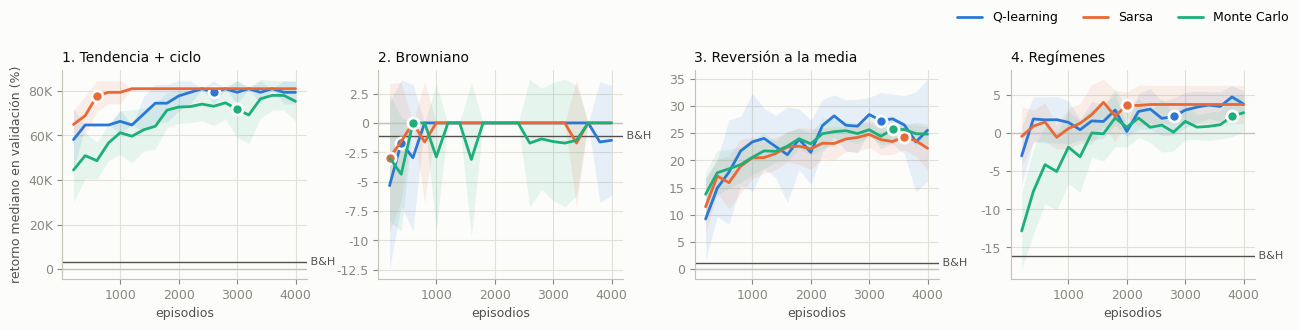

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, m in zip(axes, MERCADOS):
    val = generar_series(GENERADORES[m], 100, SEMILLA_VALIDACION)
    bh_val = evaluar(BASELINES["buy_and_hold"](), val)["retorno_pct"].median()
    ax.axhline(0, color=EJE, lw=1)
    ax.axhline(bh_val, color=TINTA_2, lw=1)
    ax.text(1.0, bh_val, " B&H", transform=ax.get_yaxis_transform(), va="center", color=TINTA_2, fontsize=8)
    for agente in ALGOS:
        d = curvas[(curvas.mercado == m) & (curvas.agente == agente)]
        g = d.groupby("episodio")["retorno_mediana_pct"]
        media, sd = g.mean(), g.std()
        color = COLORES_ALGORITMO[agente]
        ax.fill_between(media.index, media - sd, media + sd, color=color, alpha=0.1, lw=0)
        ax.plot(media.index, media.values, color=color, label=NOMBRES_ALGORITMO[agente])
        conv = runs[(runs.mercado == m) & (runs.agente == agente)]["episodio_convergencia"].median()
        ep = media.index[np.argmin(np.abs(media.index - conv))]
        ax.plot(ep, media.loc[ep], "o", ms=8, color=color, mec=FONDO, mew=2)
    ax.set_title(NOMBRES_MERCADO[m], loc="left")
    ax.set_xlabel("episodios")
    ax.yaxis.set_major_formatter(FuncFormatter(compacto))
axes[0].set_ylabel("retorno mediano en validación (%)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.9))
fig.savefig(FIGURAS / "fase4_curvas.png", dpi=200)
plt.show()

Para comparar tiempos de forma justa, medimos el coste por episodio de los tres algoritmos en la misma máquina y en el mismo proceso:

In [7]:
import time

from rl_trader.agents import entrenar

costes = {}
for m in ("ciclo", "reversion", "regimenes"):
    disc = Discretizador.ajustar(GENERADORES[m], n_intervalos=16)
    for algo in ALGOS:
        t0 = time.process_time()
        entrenar(algo, GENERADORES[m], disc, n_episodios=400, gamma=0.5, seed=7)
        costes[(NOMBRES_MERCADO[m], NOMBRES_ALGORITMO[algo])] = 1000 * (time.process_time() - t0) / 400
costes = pd.Series(costes).unstack()[[NOMBRES_ALGORITMO[a] for a in ALGOS]]
print("Milisegundos de CPU por episodio (400 episodios, sin evaluaciones):")
print(costes.round(2))

Milisegundos de CPU por episodio (400 episodios, sin evaluaciones):
                         Q-learning  Sarsa  Monte Carlo
1. Tendencia + ciclo           7.58   7.23         6.95
3. Reversión a la media        7.81   7.42         7.34
4. Regímenes                   7.70   7.15         7.03


- El coste por episodio es del mismo orden en los tres algoritmos (7–10 ms según la ejecución, y MC nunca es el más caro): MC guarda la trayectoria y la recorre una vez hacia atrás, y TD actualiza en cada paso. Así que **el tiempo de convergencia es proporcional a los episodios**.
- MC necesita más episodios en tres de los cuatro mercados: 3100 en ciclo (Sarsa, 600), 3800 en regímenes (Sarsa, 2000) y 600 en browniano (Sarsa, 200). En reversión los tres tardan algo parecido (3300–3700).
- En **regímenes** la curva de MC sigue subiendo a los 4000 episodios: no ha terminado de converger. Es la otra cara de la varianza de $G_t$: cada actualización es más ruidosa, y hacen falta más episodios para promediarla.

## 5. Políticas aprendidas

Fracción de las 10 semillas que está dentro del mercado en cada estado, para Sarsa y MC ajustados.

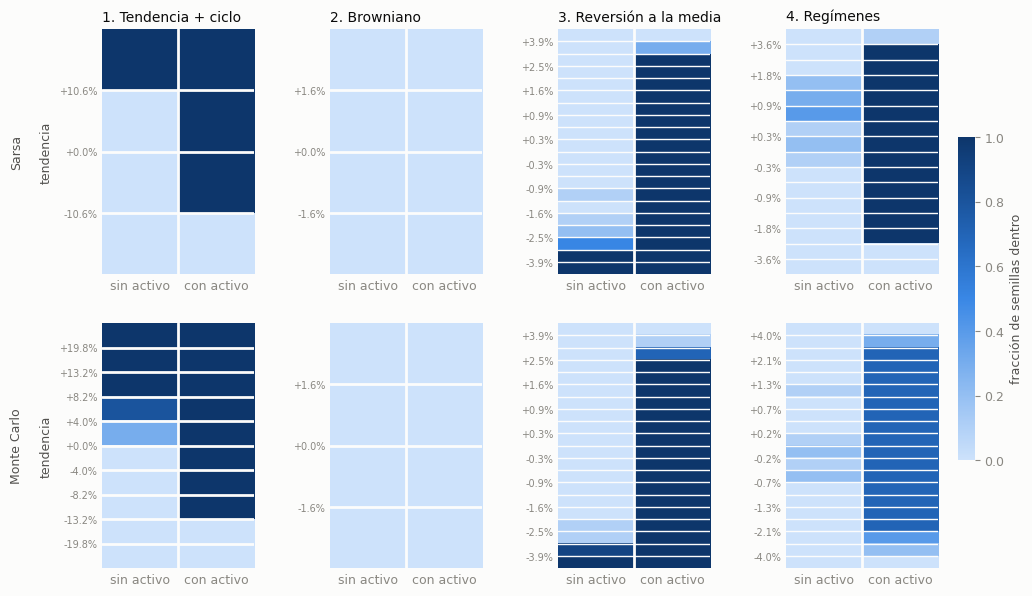

In [8]:
def efectiva(cadena):
    v = np.array(list(cadena), dtype=int)
    if not v[0::2].any():
        v[1::2] = 0
    return v


fig, axes = plt.subplots(2, 4, figsize=(13, 7), gridspec_kw={"wspace": 0.5})
for i, agente in enumerate(("sarsa", "montecarlo")):
    for j, m in enumerate(MERCADOS):
        r = runs[(runs.mercado == m) & (runs.agente == agente)]
        n = int(r["n_intervalos"].iloc[0])
        dentro = np.mean([efectiva(p) for p in r["politica"]], axis=0).reshape(n, 2)
        ax = axes[i, j]
        im = ax.imshow(dentro, cmap=SECUENCIAL, vmin=0, vmax=1, aspect="auto", origin="lower")
        cortes = Discretizador.ajustar(GENERADORES[m], n_intervalos=n).cortes
        paso = 1 if n <= 10 else 2
        posiciones = np.arange(1, n)[::-1][::paso][::-1]
        ax.set_yticks(posiciones - 0.5, [f"{100 * cortes[k - 1]:+.1f}%" for k in posiciones], fontsize=7)
        ax.set_xticks([0, 1], ["sin activo", "con activo"])
        ax.tick_params(length=0)
        ax.grid(False)
        for lado in ax.spines.values():
            lado.set_visible(False)
        for k in range(1, n):
            ax.axhline(k - 0.5, color=FONDO, lw=1 if n > 10 else 2)
        ax.axvline(0.5, color=FONDO, lw=2)
        if i == 0:
            ax.set_title(NOMBRES_MERCADO[m], loc="left")
    axes[i, 0].set_ylabel(f"{NOMBRES_ALGORITMO[agente]}\n\ntendencia")
cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.02)
cb.set_label("fracción de semillas dentro", color=TINTA_2)
cb.outline.set_visible(False)
fig.savefig(FIGURAS / "fase4_politicas.png", dpi=200, bbox_inches="tight")
plt.show()

- **Ciclo:** MC aprende el mismo momentum con histéresis que Sarsa, con más intervalos ($k = 10$) y una entrada algo más temprana.
- **Reversión:** misma configuración, misma estrategia: contrarian selectivo, que compra solo en las tendencias más bajistas y mantiene hasta las más alcistas.
- **Regímenes:** MC mantiene la posición en casi todos los estados, pero apenas compra. Con $\gamma = 0{,}5$, el valor de entrar no compensa la comisión, porque no ve lo que se gana al mantener la posición durante el régimen alcista.

## 6. Conclusiones

**Se cumplen las dos predicciones de las slides, cada una donde tocaba.** El experimento controlado aísla el efecto del objetivo (retorno real frente a *bootstrap*) y muestra el compromiso sesgo-varianza entre MC y TD:

- **Reversión ($\gamma = 0{,}5$): gana la falta de sesgo de MC.** Cambiar solo el objetivo mejora el capital final un 4% (×1,04 [1,02; 1,05]) y reduce mucho la variabilidad entre semillas. Con un horizonte efectivo corto, la varianza de $G_t$ es pequeña y pesa más el sesgo del *bootstrap* sobre un estado que no es markoviano: le falta la distancia a la media de largo plazo.
- **Regímenes ($\gamma$ alto): pierde por la varianza.** Con la configuración de Sarsa ($\gamma = 0{,}99$), MC empeora (×0,94 [0,91; 0,97]). Ajustado, huye de los $\gamma$ altos y se queda en una política que casi no compra (0% de mediana). Aun así supera a buy & hold, a momentum y a no operar.
- **Ciclo y browniano ($\gamma = 0$): idénticos.** MC con la configuración de Sarsa da exactamente la misma política y el mismo resultado, como predice la teoría. Sirve además de comprobación de la implementación.

**Convergencia.** Con el mismo coste por episodio, MC necesita más episodios que TD en tres de los cuatro mercados, y en regímenes aún no ha convergido a los 4000.

**Sesgo de selección, otra vez.** En ciclo, la configuración de MC elegida en validación (primera visita, $k = 10$) queda por debajo de la de Sarsa en test (×0,87, no significativo), aunque con la configuración de Sarsa MC iguala a Sarsa. Elegir entre muchas configuraciones con 3 semillas sobreajusta a la validación, como ya se vio en la fase 3.

**En resumen:** MC no mejora a TD en general, y no esperábamos que lo hiciera, pero el resultado de cada mercado se explica por la teoría vista en clase. Es una buena prueba de que entendemos *por qué* aprenden lo que aprenden los agentes.